# Week 5 – Tasks 2, 3 & 4: Basic Neural Network on the Breast Cancer Dataset
**Domain:** Artificial Intelligence | **Tools:** Python, TensorFlow/Keras

Goal: predict whether a tumour is **malignant** or **benign** from 30 numeric measurements.

## Task 2 – Build a Basic Neural Network
### Step 1: Import libraries

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

np.random.seed(42); tf.random.set_seed(42)
tf.config.experimental.enable_op_determinism()
print('TensorFlow version:', tf.__version__)

I0000 00:00:1793615962.023073    1288 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793615962.078615    1288 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793615963.776258    1288 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


### Step 2: Load the dataset

In [2]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
print('Shape:', df.shape)
print('Classes:', dict(enumerate(data.target_names)))
print('Missing values:', df.isnull().sum().sum())
df.head()

Shape: (569, 31)
Classes: {0: np.str_('malignant'), 1: np.str_('benign')}
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
print(df['target'].value_counts().rename({0:'malignant',1:'benign'}))
df.iloc[:, :6].describe().round(2)

target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
count,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10
std,3.52,4.30,24.30,351.91,0.01,0.05
min,6.98,9.71,43.79,143.50,0.05,0.02
25%,11.70,16.17,75.17,420.30,0.09,0.06
50%,13.37,18.84,86.24,551.10,0.10,0.09
75%,15.78,21.80,104.10,782.70,0.11,0.13
max,28.11,39.28,188.50,2501.00,0.16,0.35


### Step 3: Prepare features (X) and target (y)

In [4]:
X = data.data          # 569 samples x 30 features
y = data.target        # 0 = malignant, 1 = benign
print('X shape:', X.shape, '| y shape:', y.shape)

X shape: (569, 30) | y shape: (569,)


### Step 4: Split into training and testing data (80/20, stratified)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (455, 30)  Test: (114, 30)


### Step 5: Preprocess – feature scaling
Neural networks train best when inputs are on a similar scale. The scaler is **fitted on training data only** to avoid data leakage.

In [6]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)
print('Train mean ~', X_train.mean().round(3), '| std ~', X_train.std().round(3))

Train mean ~ -0.0 | std ~ 1.0


### Step 6: Create the neural network (input, hidden and output layers)

In [7]:
model = keras.Sequential([
    layers.Input(shape=(30,)),              # Input layer: 30 features
    layers.Dense(16, activation='relu'),    # Hidden layer 1
    layers.Dense(8,  activation='relu'),    # Hidden layer 2
    layers.Dense(1,  activation='sigmoid')  # Output layer: probability of benign
], name='breast_cancer_ann')
model.summary()

Model: "breast_cancer_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

**Architecture:** 30 → 16 (ReLU) → 8 (ReLU) → 1 (Sigmoid). Parameters: (30×16+16) + (16×8+8) + (8×1+1) = 496 + 136 + 9 = **641**.

### Step 7: Compile the model
- **Optimizer:** Adam  - **Loss:** binary cross-entropy  - **Metric:** accuracy

In [8]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss='binary_crossentropy', metrics=['accuracy'])

### Step 8: Train the model (Task 3 uses this training history)
We use 50 epochs with 20% of the training data held out as a **validation set**.

In [9]:
history = model.fit(X_train, y_train, epochs=50, batch_size=16,
                    validation_split=0.2, verbose=2)

Epoch 1/50


E0000 00:00:1793615964.856960    1288 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


23/23 - 2s - 71ms/step - accuracy: 0.6731 - loss: 0.6297 - val_accuracy: 0.7912 - val_loss: 0.5283


Epoch 2/50


23/23 - 0s - 6ms/step - accuracy: 0.8681 - loss: 0.4633 - val_accuracy: 0.8791 - val_loss: 0.4015


Epoch 3/50


... (91 outputs left out)

Epoch 49/50


23/23 - 0s - 10ms/step - accuracy: 0.9918 - loss: 0.0242 - val_accuracy: 1.0000 - val_loss: 0.0213


Epoch 50/50


23/23 - 0s - 12ms/step - accuracy: 0.9918 - loss: 0.0234 - val_accuracy: 1.0000 - val_loss: 0.0208


## Task 3 – Visualise the Training
### Accuracy and Loss curves

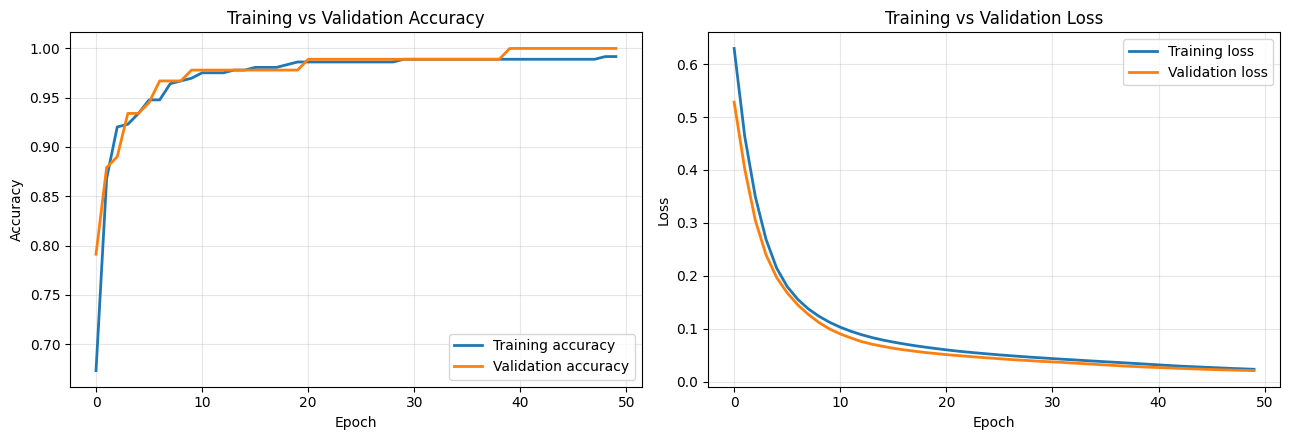

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(history.history['accuracy'], label='Training accuracy', lw=2)
ax[0].plot(history.history['val_accuracy'], label='Validation accuracy', lw=2)
ax[0].set_title('Training vs Validation Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(history.history['loss'], label='Training loss', lw=2)
ax[1].plot(history.history['val_loss'], label='Validation loss', lw=2)
ax[1].set_title('Training vs Validation Loss'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig('task3_curves.png', dpi=150); plt.show()

In [11]:
h = history.history
print(f"Epoch  1 -> train acc {h['accuracy'][0]:.3f} | val acc {h['val_accuracy'][0]:.3f} | train loss {h['loss'][0]:.3f} | val loss {h['val_loss'][0]:.3f}")
print(f"Epoch 50 -> train acc {h['accuracy'][-1]:.3f} | val acc {h['val_accuracy'][-1]:.3f} | train loss {h['loss'][-1]:.3f} | val loss {h['val_loss'][-1]:.3f}")
print('Lowest val loss at epoch', int(np.argmin(h['val_loss']))+1, '=', round(min(h['val_loss']),4))

Epoch  1 -> train acc 0.673 | val acc 0.791 | train loss 0.630 | val loss 0.528
Epoch 50 -> train acc 0.992 | val acc 1.000 | train loss 0.023 | val loss 0.021
Lowest val loss at epoch 50 = 0.0208


### Explanation (Task 3)

In [12]:
print("Train/validation accuracy gap in final epoch:", round(h['accuracy'][-1]-h['val_accuracy'][-1],3))

Train/validation accuracy gap in final epoch: -0.008


**Explanation (150-200 words):**

During training, accuracy rose quickly. Training accuracy climbed from 67.3% in epoch 1 to 99.2% in epoch 50, while validation accuracy rose from 79.1% to 100%. Loss moved the opposite way: training loss fell from 0.630 to 0.023 and validation loss from 0.528 to 0.021, with the steepest drop in the first 10 to 15 epochs. The model is clearly improving, and the flattening curves show it is close to convergence. I see no strong sign of overfitting, because validation loss is still falling, tracks training loss closely, and validation accuracy is not below training accuracy. Overfitting would appear as training loss continuing to fall while validation loss rises and the accuracy gap widens. One caution: the validation set holds only 91 samples, so 100% validation accuracy is optimistic. The test accuracy of 95.6% is the more honest figure. EarlyStopping or Dropout would be sensible safeguards, and training for more epochs is unlikely to help much because the curves have already levelled off.

## Task 4 – Model Evaluation & Prediction
### Test accuracy

In [13]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_acc*100:.2f}%')

Test loss: 0.0987 | Test accuracy: 95.61%


E0000 00:00:1793615979.459461    1288 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


### Generate predictions and compare actual vs predicted

In [14]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)
names = np.array(['Malignant','Benign'])
cmp = pd.DataFrame({'Actual': names[y_test], 'Predicted': names[y_pred],
                    'P(Benign)': y_prob.round(3)})
cmp['Correct?'] = np.where(y_test==y_pred, 'Yes', 'No')
cmp.head(10)

,Actual,Predicted,P(Benign),Correct?
0,Malignant,Malignant,0.000,Yes
1,Benign,Benign,1.000,Yes
2,Malignant,Malignant,0.001,Yes
3,Benign,Malignant,0.381,No
4,Malignant,Malignant,0.000,Yes
5,Benign,Benign,0.998,Yes
6,Benign,Benign,1.000,Yes
7,Malignant,Malignant,0.000,Yes
8,Malignant,Malignant,0.000,Yes
9,Malignant,Malignant,0.000,Yes


In [15]:
# Show the wrong predictions (if any)
cmp[cmp['Correct?']=='No']

,Actual,Predicted,P(Benign),Correct?
3,Benign,Malignant,0.381,No
33,Benign,Malignant,0.444,No
38,Benign,Malignant,0.492,No
53,Malignant,Benign,0.986,No
66,Benign,Malignant,0.287,No


### Confusion matrix and classification report

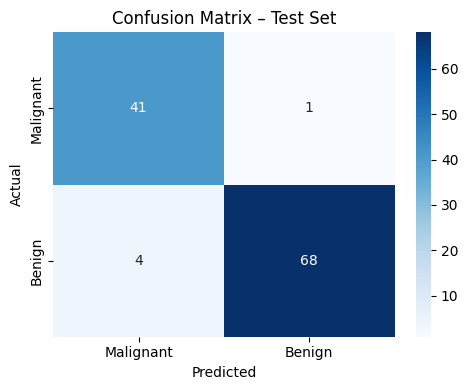

              precision    recall  f1-score   support

   Malignant       0.91      0.98      0.94        42
      Benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



In [16]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix – Test Set')
plt.tight_layout(); plt.savefig('task4_confusion.png', dpi=150); plt.show()
print(classification_report(y_test, y_pred, target_names=names))

In [17]:
tn, fp, fn, tp = cm.ravel()
# Positive class = Benign (1). cm = [[TN, FP], [FN, TP]]
print(f'Benign predicted as Malignant (false alarms)         : {fn}')
print(f'Malignant predicted as Benign (missed cancers - worst): {fp}')

Benign predicted as Malignant (false alarms)         : 4
Malignant predicted as Benign (missed cancers - worst): 1


### Explanation of incorrect predictions

The model made 5 errors on 114 test samples (95.6% accuracy). Four were benign tumours predicted as malignant, with P(benign) between 0.29 and 0.49, so they were borderline cases near the decision threshold; these are false alarms that would lead to extra tests. One was a malignant tumour predicted as benign with high confidence (P(benign) = 0.986). This is the most serious type of error, because a real cancer would be missed. Such cases usually have measurements (radius, texture, concavity) that resemble benign tumours. Malignant recall is 0.98, which is good, but a real system should lower the threshold to reduce missed cancers and validate with cross-validation and more data.